<a href="https://colab.research.google.com/github/huybla166/AIO_exercise/blob/master/Unet_%2B_RABM_dsb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

%cd '/content/drive/MyDrive/My_Prj'
# ISIC_DATA_PATH = '/content/drive/MyDrive/IPSAL_train_segment/ISIC2018_train_test.npz'

Mounted at /content/drive
/content/drive/.shortcut-targets-by-id/1hq7Jltyxmg1p_nPmUe0tA2n-I_tcz5bI/My_Prj


In [ ]:
import pdb
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random

In [ ]:
!pip install albumentations==1.3.1
import albumentations
from albumentations.pytorch import ToTensorV2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.7/125.7 kB 6.0 MB/s eta 0:00:00
  Attempting uninstall: albumentations
    Found existing installation: albumentations 2.0.8
    Uninstalling albumentations-2.0.8:
      Successfully uninstalled albumentations-2.0.8


In [ ]:
def reset_seed():
    torch.manual_seed(42)
    random.seed(42)
    torch.cuda.manual_seed(42)

# Load Data

In [ ]:
import os
import numpy as np
from PIL import Image
import albumentations as A
from albumentations.augmentations.geometric.resize import Resize   # <-- quan trọng
from albumentations.pytorch import ToTensorV2                      # <-- quan trọng
from torch.utils.data import Dataset

class QU_Dataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None, state=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.images = sorted(os.listdir(image_dir))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        img_name = self.images[index]
        img_path = os.path.join(self.image_dir, img_name)
        # mask đổi .bmp -> _anno.bmp
        mask_name = img_name.replace(".bmp", "_anno.bmp")
        mask_path = os.path.join(self.mask_dir, mask_name)

        # Đọc ảnh & mask
        image = np.array(Image.open(img_path).convert("RGB"))
        mask = np.array(Image.open(mask_path).convert("L"))  # 1 kênh

        # Nhị phân hoá mask
        mask = (mask >= 1).astype(np.uint8)  # 0/1

        if self.transform is not None:
            aug = self.transform(image=image, mask=mask)
            image = aug["image"]
            mask = aug["mask"]
        return image, mask

class DataScienceBowl(Dataset):
    def __init__(self, images, masks, transform=None):
        self.images = images
        self.masks = masks
        self.transform = transform

    def __len__(self):
        return self.images.shape[0]

    def __getitem__(self, index):
        image = self.images[index].astype("float32")
        mask = self.masks[index].squeeze().astype(np.uint8)  # HxW, 0/1

        if self.transform is not None:
            aug = self.transform(image=image, mask=mask)
            image = aug["image"]
            mask = aug["mask"]
        return image, mask

# --------- Transforms ----------
IMAGE_HEIGHT = 224
IMAGE_WIDTH = 224

train_transform = A.Compose([
    Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH, p=1.0),
    A.Rotate(limit=20, p=1.0),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.1),
    A.Normalize(mean=(0.0, 0.0, 0.0),
                std=(1.0, 1.0, 1.0),
                max_pixel_value=255.0),
    ToTensorV2(),
])

val_transform = A.Compose([
    Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH, p=1.0),
    A.Normalize(mean=(0.0, 0.0, 0.0),
                std=(1.0, 1.0, 1.0),
                max_pixel_value=255.0),
    ToTensorV2(),
])

In [ ]:
import numpy as np
x_train_dir = "/content/drive/MyDrive/My_Prj/data science bowl 2018/train_1.npy"
y_train_dir =  "/content/drive/MyDrive/My_Prj/data science bowl 2018/train_mask_1.npy"
x_test_dir =  "/content/drive/MyDrive/My_Prj/data science bowl 2018/test_real.npy"
y_test_dir =  "/content/drive/MyDrive/My_Prj/data science bowl 2018/test_real_mask.npy"
x_train = np.load(x_train_dir)
y_train = np.load(y_train_dir)
x_test = np.load(x_test_dir)
y_test = np.load(y_test_dir)


In [ ]:
train_data = DataScienceBowl(x_train,y_train,transform=train_transform)
test_data = DataScienceBowl(x_test,y_test,transform=val_transform)

torch.FloatTensor
tensor(1, dtype=torch.uint8)
torch.FloatTensor
tensor(1, dtype=torch.uint8)
torch.FloatTensor
tensor(1, dtype=torch.uint8)
torch.FloatTensor
tensor(1, dtype=torch.uint8)
torch.FloatTensor
tensor(1, dtype=torch.uint8)


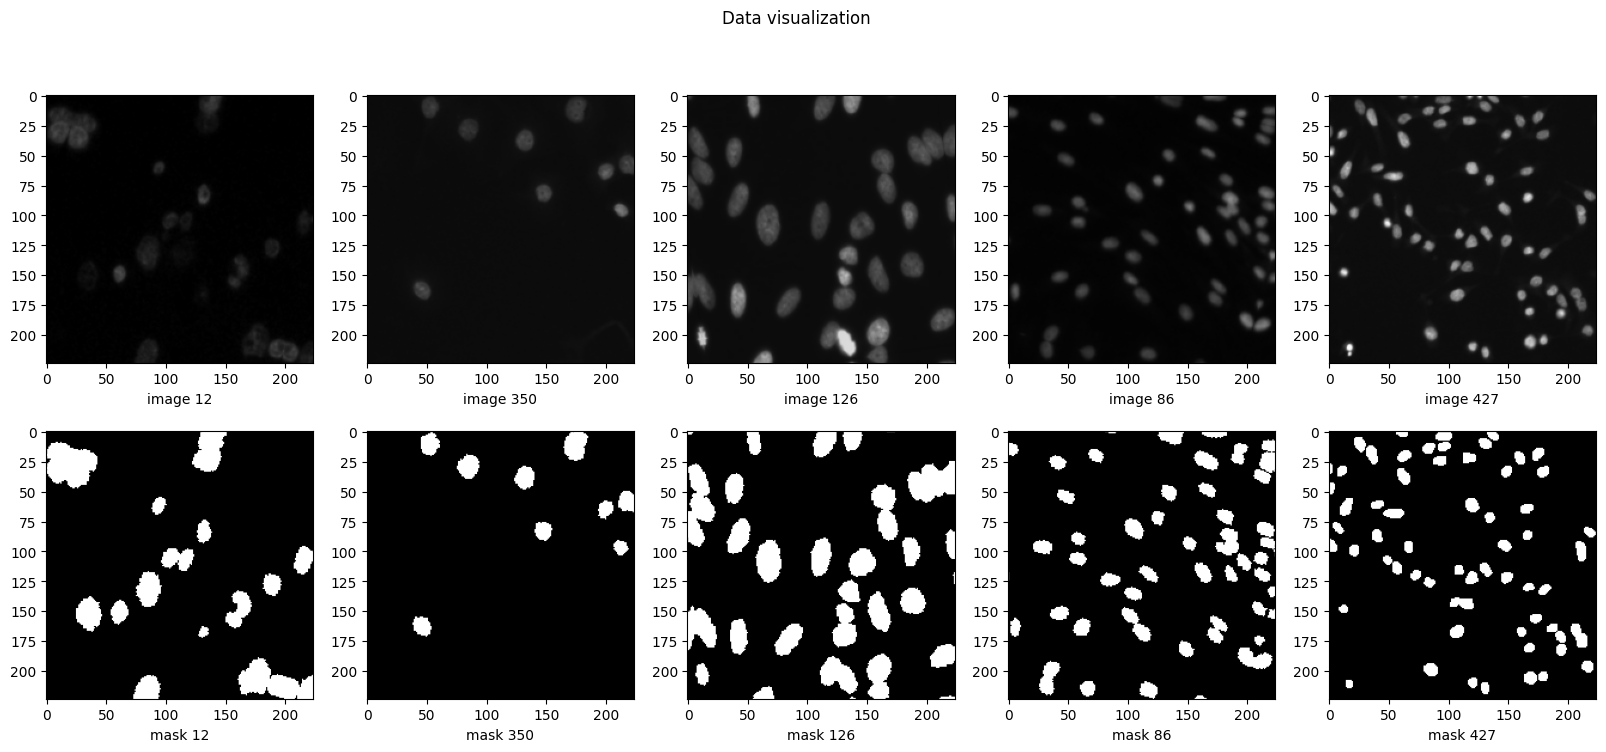

In [ ]:
# Visualize input data
import numpy as np
import matplotlib.pyplot as plt
NumSamples = 5

k = np.random.randint(len(train_data)*0.8,size = NumSamples)
fg , ax = plt.subplots(2,NumSamples,figsize = (20,8))
fg.suptitle("Data visualization")

for i,j in enumerate(k):

    X, y = train_data[j]
    print(X.type())
    print(y.max())
    ax[0,i].imshow(X.permute(1,2,0))
    ax[0,i].set_xlabel('image {}'.format(j))
    ax[1,i].imshow(y, cmap='gray')
    ax[1,i].set_xlabel('mask {}'.format(j))

In [ ]:
from torch.utils.data import DataLoader
reset_seed()
BATCH_SIZE = 16
NUM_WORKERS = 0
PIN_MEMORY   = torch.cuda.is_available()
train_loader = DataLoader(
    train_data,
    batch_size = BATCH_SIZE,
    num_workers = NUM_WORKERS,
    shuffle=True,
)
"""
val_loader = DataLoader(
    val_data,

    batch_size=BATCH_SIZE,
    num_workers = NUM_WORKERS,
    pin_memory = PIN_MEMORY,
    shuffle=False
)
"""
test_loader = DataLoader(
    test_data,
    batch_size=1,
    num_workers = 0,
    shuffle=False,
)

In [ ]:
len(train_loader)

34

In [ ]:
len(test_loader)

134

# UNet

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ChannelAttentionBAM(nn.Module):
    def __init__(self, channels: int, reduction: int = 16):
        super().__init__()
        hidden = max(8, channels // reduction)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc1 = nn.Linear(channels, hidden, bias=False)
        self.bn1 = nn.BatchNorm1d(hidden)
        self.relu = nn.ReLU(inplace=True)
        self.fc2 = nn.Linear(hidden, channels, bias=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, c, _, _ = x.shape
        y = self.gap(x).view(b, c)         # B,C
        y = self.fc2(self.relu(self.bn1(self.fc1(y))))  # B,C
        y = y.view(b, c, 1, 1)              # B,C,1,1
        return y                             # raw logits (no sigmoid)


class SpatialAttentionBAM(nn.Module):
    def __init__(self, channels: int, reduction: int = 16, dilation: int = 4):
        super().__init__()
        mid = max(8, channels // reduction)

        self.reduce = nn.Sequential(
            nn.Conv2d(channels, mid, kernel_size=1, bias=False),
            nn.BatchNorm2d(mid),
            nn.ReLU(inplace=True),
        )
        # depthwise dilated convs to enlarge receptive field cheaply
        self.dw1 = nn.Sequential(
            nn.Conv2d(mid, mid, kernel_size=3, padding=dilation, dilation=dilation,
                      groups=mid, bias=False),
            nn.BatchNorm2d(mid),
            nn.ReLU(inplace=True),
        )
        self.dw2 = nn.Sequential(
            nn.Conv2d(mid, mid, kernel_size=3, padding=dilation, dilation=dilation,
                      groups=mid, bias=False),
            nn.BatchNorm2d(mid),
            nn.ReLU(inplace=True),
        )
        self.to1 = nn.Conv2d(mid, 1, kernel_size=1, bias=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        y = self.reduce(x)
        y = self.dw1(y)
        y = self.dw2(y)
        y = self.to1(y)            # B,1,H,W
        return y                   # raw logits (no sigmoid)


class BAM(nn.Module):
    def __init__(self, channels: int, reduction: int = 16, dilation: int = 4,
                 residual_scale: float = 1.0):
        super().__init__()
        self.ca = ChannelAttentionBAM(channels, reduction)
        self.sa = SpatialAttentionBAM(channels, reduction, dilation)
        self.residual_scale = residual_scale

        # (optional) init trick: zero last conv/linear so module starts near identity
        nn.init.zeros_(self.ca.fc2.weight)
        nn.init.zeros_(self.ca.fc2.bias)
        nn.init.zeros_(self.sa.to1.weight)
        nn.init.zeros_(self.sa.to1.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        Mc = self.ca(x)           # B,C,1,1  (logits)
        Ms = self.sa(x)           # B,1,H,W   (logits)
        M  = torch.sigmoid(Mc + Ms)      # broadcast sum -> attention map in [0,1]
        return x + self.residual_scale * (x * M)   # F + F ⊙ M

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ---------- utils ----------
class ConvBNReLU(nn.Module):
    def __init__(self, c_in, c_out, k=3, s=1, p=1, dw=False):
        super().__init__()
        if dw:
            self.net = nn.Sequential(
                nn.Conv2d(c_in, c_in, k, s, p, groups=c_in, bias=False),
                nn.Conv2d(c_in, c_out, 1, 1, 0, bias=False),
                nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)
            )
        else:
            self.net = nn.Sequential(
                nn.Conv2d(c_in, c_out, k, s, p, bias=False),
                nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)
            )
    def forward(self, x): return self.net(x)

class EncoderBlock(nn.Module):
    def __init__(self, c_in, c_out, dw=False):
        super().__init__()
        self.conv1 = ConvBNReLU(c_in, c_out, dw=dw)
        self.conv2 = ConvBNReLU(c_out, c_out, dw=dw)
        self.down  = nn.Conv2d(c_out, c_out, 3, stride=2, padding=1)  # /2
    def forward(self, x):
        identity = self.conv2(self.conv1(x)) # Output before downsampling (skip connection)
        downsampled = self.down(identity)    # Downsampled output
        return downsampled, identity  # return downsampled output first, then skip connection

class UpBlock(nn.Module):
    def __init__(self, c_in, c_out, dw=False):
        super().__init__()
        self.conv1 = ConvBNReLU(c_in,  c_out, dw=dw)
        self.conv2 = ConvBNReLU(c_out, c_out, dw=dw)
    def forward(self, x):
        x = self.conv1(x); x = self.conv2(x)
        return x

# ---------- CBAM parts ----------
class _MLP(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        self.fc1 = nn.Linear(c, c // r, bias=False)
        self.relu = nn.ReLU(inplace=True)
        self.fc2 = nn.Linear(c // r, c, bias=False)
    def forward(self, x):  # x: B,C
        return self.fc2(self.relu(self.fc1(x)))

class CBAMChannel(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        self.mlp = _MLP(c, r)
    def forward(self, x):   # B,C,H,W
        b,c,_,_ = x.shape
        avg = F.adaptive_avg_pool2d(x,1).view(b,c)
        mx  = F.adaptive_max_pool2d(x,1).view(b,c)
        w_c = torch.sigmoid(self.mlp(avg) + self.mlp(mx)).view(b,c,1,1)
        return x * w_c

class CBAMSpatial(nn.Module):
    def __init__(self, k=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=k, padding=k//2, bias=False)
    def forward(self, x):
        avg = torch.mean(x,  dim=1, keepdim=True)
        mx,_ = torch.max(x,  dim=1, keepdim=True)
        return torch.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))  # B,1,H,W

class DilatedSpatial(nn.Module):
    def __init__(self, c, r=16, dilation=4):
        super().__init__()
        mid = max(8, c // r)
        self.reduce = nn.Conv2d(c, mid, 1)
        self.bn1 = nn.BatchNorm2d(mid); self.bn2 = nn.BatchNorm2d(mid); self.bn3 = nn.BatchNorm2d(mid)
        self.relu = nn.ReLU(inplace=True)
        self.d1 = nn.Conv2d(mid, mid, 3, padding=dilation, dilation=dilation, groups=mid)
        self.d2 = nn.Conv2d(mid, mid, 3, padding=dilation, dilation=dilation, groups=mid)
        self.out = nn.Conv2d(mid, 1, 1)
    def forward(self, x):
        y = self.relu(self.bn1(self.reduce(x)))
        y = self.relu(self.bn2(self.d1(y)))
        y = self.relu(self.bn3(self.d2(y)))
        return torch.sigmoid(self.out(y))  # B,1,H,W

# ---------- GBeta gate (optional) ----------
class GBeta(nn.Module):
    """
    Per-pixel β map from both encoder and decoder signals, very light.
    β = σ( fe(xe) ⊙ fd(xd_logit) ), shape B×1×H×W
    """
    def __init__(self, c):
        super().__init__()
        self.fe = nn.Sequential(                       # from encoder (C channels)
            nn.Conv2d(c, c, 3, padding=1, groups=c),
            nn.Conv2d(c, 1, 1)
        )
        self.fd = nn.Sequential(                       # from coarse logit (1 channel)
            nn.Conv2d(1, 1, 3, padding=1),
            nn.Conv2d(1, 1, 1)
        )
    def forward(self, xe, xd_logit):
        be = self.fe(xe)                  # B,1,H,W
        bd = self.fd(xd_logit)            # B,1,H,W
        return torch.sigmoid(be * bd)     # B,1,H,W

# ---------- RABM: CBAM-Channel + DPSA + Reverse ----------
class RABM_CBAM_DPSA(nn.Module):
    """
    xe: encoder feature (B,C,H,W)
    xd_logit: coarse logit (B,1,h,w) -- will be resized to match H×W
    """
    def __init__(self, c, reduction=16, k=7, dilation=4, use_residual=True, use_gbeta=False):
        super().__init__()
        self.channel = CBAMChannel(c, r=reduction)
        self.spaA = CBAMSpatial(k=k)
        self.spaB = DilatedSpatial(c, r=reduction, dilation=dilation)
        self.beta_fc = nn.Conv2d(c, 1, 1)             # scalar-like β (via GAP) if not GBeta
        self.gbeta = GBeta(c) if use_gbeta else None
        self.use_residual = use_residual

    def forward(self, xe, xd_logit):
        # resize coarse logit to xe spatial size if needed
        if xd_logit.shape[-2:] != xe.shape[-2:]:
            xd_logit = F.interpolate(xd_logit, size=xe.shape[-2:], mode='bilinear', align_corners=False)

        # Channel attention
        y = self.channel(xe)

        # Spatial dual path
        sA = self.spaA(xe)
        sB = self.spaB(xe)

        if self.gbeta is not None:
            beta = self.gbeta(xe, xd_logit)                  # B,1,H,W
        else:
            beta = torch.sigmoid(self.beta_fc(F.adaptive_avg_pool2d(xe,1)))  # B,1,1,1

        S = beta * sB + (1 - beta) * sA
        y = y * S

        # Reverse attention
        mask = 1.0 - torch.sigmoid(xd_logit)                 # B,1,H,W
        y = y * mask.expand_as(y)

        # Residual is handled outside
        return y


# ---------- Model: UNet + RABM with coarse logits ----------
class UNet_RABM(nn.Module):
    """
    Simple UNet-like with RABM at 1/8 and 1/4.
    - coarse16 from bottleneck (1/16), upsampled to 1/4 for RABM@1/4
    - coarse8 from decoder@1/8 for RABM@1/8
    """
    def __init__(self, num_classes=1, base_ch=[64,128,256,512], dw=False,
                 use_gbeta=False):
        super().__init__()
        c1,c2,c3,c4 = base_ch

        # Encoder
        self.enc1 = EncoderBlock(3,  c1, dw) # output: downsampled (1/2), skip (1/1)
        self.enc2 = EncoderBlock(c1, c2, dw) # output: downsampled (1/4), skip (1/2)
        self.enc3 = EncoderBlock(c2, c3, dw) # output: downsampled (1/8), skip (1/4)
        self.enc4 = EncoderBlock(c3, c4, dw) # output: downsampled (1/16), skip (1/8)


        # Bottleneck (2 convs gọn)
        self.bot1 = ConvBNReLU(c4, c4, dw=dw)
        self.bot2 = ConvBNReLU(c4, c4, dw=dw)

        # Decoder
        self.up_16_to_8 = UpBlock(c4 + c4, c3, dw)    # -> 1/8 (Concatenate bottleneck output with upsampled feature)
        self.up_8_to_4  = UpBlock(c3 + c3, c2, dw)    # -> 1/4 (Concatenate)
        self.up_4_to_2  = UpBlock(c2 + c2, c1, dw)    # -> 1/2 (Concatenate)
        self.up_2_to_1  = UpBlock(c1 + c1, c1, dw)    # -> 1/1 (Concatenate)


        # Coarse logits
        self.coarse16 = nn.Conv2d(c4, 1, 1)      # from bottleneck (1/16)
        self.coarse8  = nn.Conv2d(c3, 1, 1)      # from decoder@1/8

        # RABM blocks
        # RABM@1/8 uses skip from enc3 (1/4 resolution) and coarse8 (1/8 resolution) - need to adjust
        # RABM@1/4 uses skip from enc2 (1/2 resolution) and coarse16 upsampled (1/4 resolution) - need to adjust
        self.rabm8 = RABM_CBAM_DPSA(c3, reduction=16, k=7, dilation=4, use_residual=False, use_gbeta=use_gbeta) # Channels for 1/8 res
        self.rabm4 = RABM_CBAM_DPSA(c2, reduction=16, k=7, dilation=2, use_residual=False, use_gbeta=use_gbeta) # Channels for 1/4 res
        self.bam1 = BAM(c1, reduction=16, dilation=4)
        self.bam2 = BAM(c2, reduction=16, dilation=4)
        # Head
        self.head = nn.Conv2d(c1, num_classes, 1)

    def forward(self, x):
        H,W = x.shape[-2:]

        # Encoder
        x1_down, s1 = self.enc1(x)   # x1_down: @1/2, s1: @1/1
        x2_down, s2 = self.enc2(x1_down)   # x2_down: @1/4, s2: @1/2
        x3_down, s3 = self.enc3(x2_down)   # x3_down: @1/8, s3: @1/4
        x4_down, s4 = self.enc4(x3_down)   # x4_down: @1/16, s4: @1/8


        # Bottleneck
        x = self.bot2(self.bot1(x4_down))              # 1/16
        coarse16 = self.coarse16(x)              # B,1, H/16, W/16

        # up to 1/8
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False) # B,c4, H/8, W/8
        # Concatenate skip connection s4 at 1/8 resolution
        x = torch.cat([x, s4], dim=1)
        x = self.up_16_to_8(x)                   # B,c3,H/8,W/8
        coarse8 = self.coarse8(x)                # B,1,H/8,W/8

        # RABM @1/8 (xe = x, xd = coarse8). x is at 1/8 resolution
        rabm8_out = self.rabm8(x, coarse8) # Temporarily remove RABM
        x = x + rabm8_out # Add RABM output as residual


        # up to 1/4
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False) # B,c3, H/4, W/4
        # Concatenate skip connection s3 at 1/4 resolution
        x = torch.cat([x, s3], dim=1)
        x = self.up_8_to_4(x)                    # B,c2,H/4,W/4

        # RABM @1/4 (xe = x, xd = coarse16 upsampled). x is at 1/4 resolution
        # Upsample coarse16 to match 1/4 resolution
        coarse16_up = F.interpolate(coarse16, size=(H//4, W//4), mode='bilinear', align_corners=False)
        rabm4_out = self.rabm4(x, coarse16_up) # Temporarily remove RABM
        x = x + rabm4_out # Add RABM output as residual


        # up to 1/2
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False) # B,c2, H/2, W/2
        # Concatenate skip connection s2 at 1/2 resolution
        x = torch.cat([x, self.bam2(s2)], dim=1)
        x = self.up_4_to_2(x)                    # B,c1,H/2,W/2


        # to 1/1
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False) # B,c1, H/1, W/1
        # Concatenate skip connection s1 at 1/1 resolution
        x = torch.cat([x, self.bam1(s1)], dim=1)
        x = self.up_2_to_1(x)                    # B,c1,H,W


        out = self.head(x)                       # logits
        out = F.interpolate(out, size=(H,W), mode='bilinear', align_corners=False)
        return out

In [ ]:
if __name__ == "__main__":
    model = UNet_RABM(num_classes=1, use_gbeta=True)  # bật GBeta để “độc” hơn
    x = torch.randn(2,3,256,256) # Changed input size back to 256x256
    y = model(x)                # logits (chưa sigmoid)
    print(y.shape)              # -> torch.Size([2, 1, 256, 256])

torch.Size([2, 1, 256, 256])


# Define function

## Loss and Metric

In [ ]:
# from torch.nn.functional import cross_entropy
# from torch.nn.modules.loss import _WeightedLoss

In [ ]:
import torch
# import torch
import torch.nn as nn
import torch.utils.checkpoint as checkpoint
# from einops import rearrange
from torch.nn.functional import cross_entropy
from torch.nn.modules.loss import _WeightedLoss


EPSILON = 1e-32


class LogNLLLoss(_WeightedLoss):
    __constants__ = ['weight', 'reduction', 'ignore_index']

    def __init__(self, weight=None, size_average=None, reduce=None, reduction=None,
                 ignore_index=-100):
        super(LogNLLLoss, self).__init__(weight, size_average, reduce, reduction)
        self.ignore_index = ignore_index

    def forward(self, y_input, y_target):
        # y_input = torch.log(y_input + EPSILON)
        return cross_entropy(y_input, y_target, weight=self.weight,
                             ignore_index=self.ignore_index)


def classwise_iou(output, gt):
    """
    Args:
        output: torch.Tensor of shape (n_batch, n_classes, image.shape)
        gt: torch.LongTensor of shape (n_batch, image.shape)
    """
    #dims = (0, *range(2, len(output.shape)))
    #gt = torch.zeros_like(output).scatter_(1, gt[:, None, :], 1)
    output = torch.argmax(output, dim=1)
    intersection = output*gt
    union = output + gt - intersection
    #classwise_iou = (intersection.sum(dim=dims).float() + EPSILON) / (union.sum(dim=dims) + EPSILON)
    classwise_iou = (intersection.sum().float() + EPSILON) / (union.sum() + EPSILON)
    return classwise_iou


def classwise_f1(output, gt):
    """
    Args:
        output: torch.Tensor of shape (n_batch, n_classes, image.shape)
        gt: torch.LongTensor of shape (n_batch, image.shape)
    """

    epsilon = 1e-20
    n_classes = output.shape[1]

    output = torch.argmax(output, dim=1)
    #print(output)
    true_positives = torch.tensor([((output == i) * (gt == i)).sum() for i in range(n_classes)]).float()
    true_positives = true_positives[1].item()
    selected = ((output == 1)).sum().float()
    relevant = ((gt == 1)).sum().float()
    #selected = torch.tensor([(output == i).sum() for i in range(n_classes)]).float()
    #relevant = torch.tensor([(gt == i).sum() for i in range(n_classes)]).float()
    #print("relevant:",relevant)
    #print("selected:",selected)

    precision = (true_positives + epsilon) / (selected + epsilon)
    recall = (true_positives + epsilon) / (relevant + epsilon)
    #print(precision)
    #print(recall)
    classwise_f1 = 2 * (precision * recall + EPSILON) / (precision + recall + EPSILON)

    return classwise_f1
def classwise_dicescore(output, gt):
    """
    Args:
        output: torch.Tensor of shape (n_batch, n_classes, image.shape)
        gt: torch.LongTensor of shape (n_batch, image.shape)
    """
    epsilon = 1e-20
    n_classes = output.shape[1]

    output = torch.argmax(output, dim=1)
    #print(output)
    true_positives = torch.tensor([((output == i) * (gt == i)).sum() for i in range(n_classes)]).float()
    true_positives = true_positives[1].item()
    selected = ((output == 1)).sum().float()
    relevant = ((gt == 1)).sum().float()
    dice_score = 2 * true_positives / (selected + relevant)
    return dice_score

def make_weighted_metric(classwise_metric):
    """
    Args:
        classwise_metric: classwise metric like classwise_IOU or classwise_F1
    """

    def weighted_metric(output, gt, weights=None):

        # dimensions to sum over
        dims = (0, *range(2, len(output.shape)))

        # default weights
        if weights == None:
            weights = torch.ones(output.shape[1]) / output.shape[1]
        else:
            # creating tensor if needed
            if len(weights) != output.shape[1]:
                raise ValueError("The number of weights must match with the number of classes")
            if not isinstance(weights, torch.Tensor):
                weights = torch.tensor(weights)
            # normalizing weights
            weights /= torch.sum(weights)

        classwise_scores = classwise_metric(output, gt).cpu()

        return classwise_scores

    return weighted_metric

In [ ]:
# Implement Focal Loss
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=0, size_average=True,):
        super().__init__()
        self.gamma = gamma
        if isinstance(alpha, (float, int)):
            self.alpha = torch.tensor([alpha, 1-alpha])
        if isinstance(alpha, (list)) :
            self.alpha = torch.tensor(alpha)
        self.size_average = size_average
        #self.alpha = self.alpha.to(device)
    def forward(self, inputs, targets):
        """
        Inputs:
        targets : shape (N, 1, H, W), dtype = long
        inputs : shape (N, C, H, W) - has propability for each class

        Returns:
        Focal loss between groundtruth and predict
        """
        if inputs.dim() > 2:
            B, C, H, W = inputs.shape
            inputs = inputs.contiguous().permute(0,2,3,1) # shape (B, H, W, C)
            inputs = inputs.contiguous().reshape(B*H*W,C)
        targets = targets.reshape(-1, 1) # shape (N*H*W, 1)

        logpt = F.log_softmax(inputs, dim = 1)
        logpt = logpt.gather(1, targets)
        logpt = logpt.view(-1) # shape (N*H*W)
        pt = logpt.exp()
        #print(targets.device)
        if self.alpha is not None:
            if self.alpha.type() != inputs.data.type():
                self.alpha = self.alpha.to(inputs.dtype)
            self.alpha = self.alpha.to(inputs.device)
            at = self.alpha.gather(0, targets.view(-1))
            logpt = logpt * at
        loss = -1. * (1 - pt)**self.gamma * logpt
        if self.size_average:
            return loss.mean()
        else:
            return loss.sum()




In [ ]:
# Implement Focal Loss
class DiceLoss(nn.Module):
    def __init__(self, size_average=True,):
        super().__init__()
    def forward(self, inputs, targets):
        """
        Inputs:
        targets : shape (N, 1, H, W), dtype = long
        inputs : shape (N, C, H, W) - has propability for each class

        Returns:
        Focal loss between groundtruth and predict
        """
        if inputs.dim() > 2:
            B, C, H, W = inputs.shape
            inputs = inputs.contiguous().permute(0,2,3,1) # shape (B, H, W, C)
            inputs = inputs.contiguous().reshape(B*H*W,C)
        targets = targets.reshape(-1, 1) # shape (N*H*W, 1)

        logpt = F.log_softmax(inputs, dim = 1)
        logpt = logpt.gather(1, targets)
        logpt = logpt.view(-1) # shape (N*H*W)
        pt = logpt.exp()
        #print(targets.device)
        pt = pt.view(-1) # shape (N*H*W)
        intersection = (pt * targets.view(-1)).sum()
        #print(targets.device)
        dice = (2. * intersection + 1e-32) / (pt.sum() + targets.sum() + 1e-32)
        return 1 - dice


In [ ]:
class CEDiceloss(nn.Module):
    def __init__(self, alpha = 0.5):
        super().__init__()
        self.alpha = alpha
    def forward(self, inputs, targets):
        criterion1 = DiceLoss()
        criterion2 = nn.CrossEntropyLoss()
        return self.alpha * criterion1(inputs, targets) + (1 - self.alpha) * criterion2(inputs, targets)

In [ ]:
#output, gt = torch.ones(3, 2, 5, 5), torch.ones(3, 5, 5).long()
gt = torch.ones(3, 5, 5).long()
output = torch.stack([torch.zeros(3,5,5), torch.ones(3,5,5)], dim=1)
print(classwise_dicescore(output, gt))
print(classwise_f1(output,gt))

tensor(1.)
tensor(1.)


In [ ]:
# classwise_iou(output, gt)
# #print(output.shape)

## Def function to train and test

In [ ]:
def train_fn(loader, model,optimizer, loss_fn, scaler):

    model.train()
    train_running_loss = 0
    my_f1 = 0
    my_iou = 0
    counter = 0
    loop = tqdm(loader)
    for batch_idx, (data, targets) in enumerate(loop):
        data = data.to(device=DEVICE)
        targets = targets.long().to(DEVICE)
        # forward
        with torch.cuda.amp.autocast():
            prediction = model(data)
            loss = loss_fn(prediction, targets)
        tmp = prediction.detach().cpu()
        tmp2 = targets.detach().cpu()
        my_f1 += classwise_f1(tmp, tmp2).item()
        my_iou += classwise_iou(tmp, tmp2).item()
        # backward
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        # update tqdm loop
        loop.set_postfix(loss = loss.item())
        train_running_loss += loss.item()
        counter += 1
    scheduler.step()
    return train_running_loss / counter, my_f1/counter, my_iou/counter

def check_accuracy(loader, model, loss_fn, device="cuda"):
    my_f1 = 0
    my_iou = 0
    my_dicescore = 0
    val_running_loss = 0
    model.eval()
    with torch.no_grad():
        for X, y in loader:
            batch_size = X.shape[0]
            X = X.to(device)
            y = y.long().to(device)
            preds = model(X)
            loss = loss_fn(preds, y)
            val_running_loss += loss.item()
            tmp = preds.detach().cpu()
            tmp2 = y.detach().cpu()
            my_f1 += classwise_f1(tmp, tmp2).item()
            my_iou += classwise_iou(tmp, tmp2).item()
            my_dicescore += classwise_dicescore(tmp, tmp2).item()
    model.train()
    print(f"IoU score: {my_iou/len(loader)}")
    print(f"F1 score: {my_f1/len(loader)} ")
    print(f"Dice score: {my_dicescore/len(loader)} ")
    return val_running_loss/len(loader),my_f1/len(loader),my_iou/len(loader)


In [ ]:
def train_fn_swa(loader, model, swa_model, optimizer, loss_fn, scaler):
    model.train()
    train_running_loss = 0
    my_f1 = 0
    my_iou = 0
    counter = 0
    loop = tqdm(loader)
    for batch_idx, (data, targets) in enumerate(loop):
        data = data.to(device=DEVICE)
        targets = targets.long().to(DEVICE)

        # forward

        with torch.cuda.amp.autocast():
            prediction = model(data)
            loss = loss_fn(prediction, targets)

        tmp = prediction.detach().cpu()
        tmp2 = targets.detach().cpu()
        my_f1 += classwise_f1(tmp, tmp2).item()
        my_iou += classwise_iou(tmp, tmp2).item()

        # backward
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # update tqdm loop
        loop.set_postfix(loss = loss.item())
        train_running_loss += loss.item()
        counter += 1
    swa_model.update_parameters(model)
    swa_scheduler.step()
    bn_update(swa_model, train_loader)
    return train_running_loss / counter, my_f1/counter, my_iou/counter

# batchnormalize update running mean + running var
def bn_update(swa_model, loader):
    with torch.no_grad():
        for data, target in loader:
            data = data.to(device=DEVICE)
            #target.to(device=DEVICE)
            _ = swa_model(data)

In [ ]:
def train_normal():
    for epoch in range(0, 300):

        #model.cuda()
        print(f"=============Epoch {epoch}============>")
        if (epoch < swa_start) :
            train_loss,train_f1,train_iou = train_fn(train_loader, model, optimizer, criterion, scaler)
        else :
            train_loss,train_f1,train_iou = train_fn_swa(train_loader, model, swa_model, optimizer, criterion, scaler)
        if epoch == 10:
            for param in model.parameters():
                param.requires_grad =True


        if (epoch % save_freq) == 0:
            if (epoch >=  swa_start):
                checkpoint = {
                    "state_dict": swa_model.module.state_dict(),
                    "optimizer" : optimizer.state_dict(),
                    "epoch" : epoch + 1,
                }
                #checkpoint_history["epoch "+str(epoch+1)] = checkpoint
                save_checkpoint(checkpoint)
                print("test score:")
                test_loss,test_f1,test_iou = check_accuracy(test_loader, swa_model, criterion, DEVICE)
                if test_f1 > best_accuracy:
                    best_accuracy = test_f1
                    best_checkpoint = epoch
                    name = f"dice score {test_f1:.4f},test_score {test_iou:.4f},epoch {epoch}".replace(".",",")
                    save_checkpoint(checkpoint, filename=name+".pth.tar")
                print("train score:")
                train_loss, train_f1, train_iou = check_accuracy(train_loader, swa_model, criterion, DEVICE)
                print("train score:")
                loss_history["test"].append(test_loss)
                loss_history["train"].append(train_loss)
                acc_history["train_f1"].append(train_f1)
                acc_history["train_iou"].append(train_iou)
                acc_history["test_f1"].append(test_f1)
                acc_history["test_iou"].append(test_iou)
            else :
                checkpoint = {
                    "state_dict": model.state_dict(),
                    "optimizer" : optimizer.state_dict(),
                    "epoch" : epoch + 1,
                }
                #checkpoint_history["epoch "+str(epoch+1)] = checkpoint
                save_checkpoint(checkpoint)
                print("test score:")
                test_loss,test_f1,test_iou = check_accuracy(test_loader, model, criterion, DEVICE)
                if test_f1 > best_accuracy:
                    best_accuracy = test_f1
                    best_checkpoint = epoch
                    name = f"dice score {test_f1:.4f},test_score {test_iou:.4f},epoch {epoch}".replace(".",",")
                    save_checkpoint(checkpoint, filename=name+".pth.tar")
                print("train score:")
                train_loss, train_f1, train_iou = check_accuracy(train_loader, model, criterion, DEVICE)
                print("train score:")
                loss_history["test"].append(test_loss)
                loss_history["train"].append(train_loss)
                acc_history["train_f1"].append(train_f1)
                acc_history["train_iou"].append(train_iou)
                acc_history["test_f1"].append(test_f1)
                acc_history["test_iou"].append(test_iou)



In [ ]:
def train_eff():
    best_accuracy = 0
    for epoch in range(0, 300):

        #model.cuda()
        print(f"=============Epoch {epoch}============>")
        if (epoch < swa_start) :
            train_loss,train_f1,train_iou = train_fn(train_loader, model, optimizer, criterion, scaler)
        else :
            train_loss,train_f1,train_iou = train_fn_swa(train_loader, model, swa_model, optimizer, criterion, scaler)
        print("train score:")
        print(f"IoU score: {train_iou}")
        print(f"Dice score: {train_f1}")
        if epoch == 10:
            for param in model.parameters():
                param.requires_grad =True



        if (epoch >=  swa_start):
            #checkpoint_history["epoch "+str(epoch+1)] = checkpoint
            if (epoch % 1000 == 0 and epoch > 0):
                save_checkpoint(checkpoint,filename=f"epoch {epoch}.pth.tar")
            print("test score:")
            test_loss,test_f1,test_iou = check_accuracy(test_loader, swa_model, criterion, DEVICE)
            if test_f1 > best_accuracy:
                best_accuracy = test_f1
                checkpoint = {
                "state_dict": swa_model.module.state_dict(),
                "epoch" : epoch + 1,
            }
                name = f"dice score {test_f1:.4f},IOU_score {test_iou:.4f},epoch {epoch}".replace(".",",")
                save_checkpoint(checkpoint, filename=name+".pth.tar")
            loss_history["test"].append(test_loss)
            loss_history["train"].append(train_loss)
            acc_history["train_f1"].append(train_f1)
            acc_history["train_iou"].append(train_iou)
            acc_history["test_f1"].append(test_f1)
            acc_history["test_iou"].append(test_iou)
        else :
            #checkpoint_history["epoch "+str(epoch+1)] = checkpoint
            if (epoch % 1000 == 0 and epoch > 0):
                save_checkpoint(checkpoint,filename = f"epoch {epoch}.pth.tar")
            print("test score:")
            test_loss,test_f1,test_iou = check_accuracy(test_loader, model, criterion, DEVICE)
            if test_f1 > best_accuracy:
                best_accuracy = test_f1
                checkpoint = {
                "state_dict": model.state_dict(),
                "epoch" : epoch + 1,
            }
                name = f"dice score {test_f1:.4f},IOU_score {test_iou:.4f},epoch {epoch}".replace(".",",")
                save_checkpoint(checkpoint, filename=name+".pth.tar")
            loss_history["test"].append(test_loss)
            loss_history["train"].append(train_loss)
            acc_history["train_f1"].append(train_f1)
            acc_history["train_iou"].append(train_iou)
            acc_history["test_f1"].append(test_f1)
            acc_history["test_iou"].append(test_iou)





# Train and Test

In [ ]:
model = UNet_RABM(num_classes=2, base_ch=[64,128,256,512]).cuda()
# model = SwinTransformerSys()

In [ ]:
sum = 0
for param in model.parameters():
  sum = sum + param.numel()
print(f'total param of model is {sum}')

total param of model is 16548446


In [ ]:
from tqdm import tqdm

In [ ]:
lr = 1e-4
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# NUM_EPOCHS = 300
# NUM_EPOCHS = 100
NUM_EPOCHS = 50# đặt nhỏ để train cho nhanh
IMG_SIZE = 256
IMG_CHANEL = 3
save_freq = 1000

In [ ]:
import os
os.makedirs('/content/drive/MyDrive/My_Prj/Weight', exist_ok = True)

In [ ]:
%cd '/content/drive/MyDrive/My_Prj/Weight'

/content/drive/.shortcut-targets-by-id/1hq7Jltyxmg1p_nPmUe0tA2n-I_tcz5bI/My_Prj/Weight


In [ ]:
def save_checkpoint(state, filename="my_checkpoint_ceil_1.pth.tar"):
    print("================================================================================>Saving checkpoint")
    torch.save(state, filename)
def load_checkpoint(checkpoint, model):
    print("=> Loading checkpoint")
    model.load_state_dict(checkpoint["state_dict"])

In [ ]:
import math
base_lr        = 1e-4          # LR lớn lúc đầu
min_lr         = 1e-6          # LR về cuối
warmup_epochs  = 5             # số epoch warmup
total_epochs   = NUM_EPOCHS    # tổng epoch
swa_start      = 20            # bắt đầu SWA sau epoch này

optimizer = torch.optim.AdamW(model.parameters(), lr=base_lr, weight_decay=1e-5)

def lr_lambda(epoch):
    # epoch: 0..total_epochs-1
    if epoch < warmup_epochs:
        # tuyến tính từ 0 -> 1 trong warmup
        return (epoch + 1) / warmup_epochs
    # cosine từ 1 -> 0 sau warmup
    t = (epoch - warmup_epochs) / max(1, (total_epochs - warmup_epochs))
    cosine = 0.5 * (1.0 + math.cos(math.pi * t))
    # scale về [min_lr/base_lr, 1.0]
    return (min_lr / base_lr) + (1 - (min_lr / base_lr)) * cosine

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

In [ ]:
from torch.optim.swa_utils import AveragedModel, SWALR, update_bn

swa_model     = AveragedModel(model).cuda()
swa_scheduler = SWALR(optimizer, anneal_strategy="linear",
                      anneal_epochs=5, swa_lr=1e-5)

In [ ]:
#optimizer_1 = torch.optim.Adam(model_fake.parameters(), lr=1e-4, weight_decay=1e-4)
#swa_scheduler = torch.optim.swa_utils.SWALR(optimizer_1, swa_lr=1e-4)

In [ ]:
loss_history = {"train":[],"test":[]}
acc_history = {"train_f1":[],"test_f1":[],"train_iou":[],"test_iou":[]}
checkpoint_history = {}
best_accuracy = 0

In [ ]:
def train_eff():
    best_accuracy = 0
    for epoch in range(0, 300):

        #model.cuda()
        print(f"=============Epoch {epoch}============>")
        if (epoch < swa_start) :
            train_loss,train_f1,train_iou = train_fn(train_loader, model, optimizer, criterion, scaler)
        else :
            train_loss,train_f1,train_iou = train_fn_swa(train_loader, model, swa_model, optimizer, criterion, scaler)
        print("train score:")
        print(f"IoU score: {train_iou}")
        print(f"Dice score: {train_f1}")
        if epoch == 10:
            for param in model.parameters():
                param.requires_grad =True



        if (epoch >=  swa_start):
            #checkpoint_history["epoch "+str(epoch+1)] = checkpoint
            if (epoch % 1000 == 0 and epoch > 0):
                save_checkpoint(checkpoint,filename=f"epoch {epoch}.pth.tar")
            print("test score:")
            test_loss,test_f1,test_iou = check_accuracy(test_loader, swa_model, criterion, DEVICE)
            if test_f1 > best_accuracy:
                best_accuracy = test_f1
                checkpoint = {
                "state_dict": swa_model.module.state_dict(),
                "epoch" : epoch + 1,
            }
                name = f"dice score {test_f1:.4f},IOU_score {test_iou:.4f},epoch {epoch}".replace(".",",")
                save_checkpoint(checkpoint, filename=name+".pth.tar")
            loss_history["test"].append(test_loss)
            loss_history["train"].append(train_loss)
            acc_history["train_f1"].append(train_f1)
            acc_history["train_iou"].append(train_iou)
            acc_history["test_f1"].append(test_f1)
            acc_history["test_iou"].append(test_iou)
        else :
            #checkpoint_history["epoch "+str(epoch+1)] = checkpoint
            if (epoch % 1000 == 0 and epoch > 0):
                save_checkpoint(checkpoint,filename = f"epoch {epoch}.pth.tar")
            print("test score:")
            test_loss,test_f1,test_iou = check_accuracy(test_loader, model, criterion, DEVICE)
            if test_f1 > best_accuracy:
                best_accuracy = test_f1
                checkpoint = {
                "state_dict": model.state_dict(),
                "epoch" : epoch + 1,
            }
                name = f"dice score {test_f1:.4f},IOU_score {test_iou:.4f},epoch {epoch}".replace(".",",")
                save_checkpoint(checkpoint, filename=name+".pth.tar")
            loss_history["test"].append(test_loss)
            loss_history["train"].append(train_loss)
            acc_history["train_f1"].append(train_f1)
            acc_history["train_iou"].append(train_iou)
            acc_history["test_f1"].append(test_f1)
            acc_history["test_iou"].append(test_iou)

In [ ]:
reset_seed()
test_loader_final = DataLoader(
    test_data,
    batch_size=1,
    num_workers = 0,
    shuffle=True,
)

In [ ]:
criterion = CEDiceloss(alpha = 0.5)
scaler = torch.cuda.amp.GradScaler()

/tmp/ipython-input-1139003547.py:2: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


In [ ]:
!pip -q install fvcore
import torch, importlib

# Tạm biến torch.jit.script thành no-op chỉ trong lúc import fvcore
_orig_script = torch.jit.script
torch.jit.script = lambda fn, *a, **k: fn
from fvcore.nn import FlopCountAnalysis, flop_count_table
torch.jit.script = _orig_script  # khôi phục

# Đếm FLOPs
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device).eval()   # dùng model của bạn
x = torch.rand(1, 3, 256, 256, device=device)

flops = FlopCountAnalysis(model, x)
print(flop_count_table(flops))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
| module                    | #parameters or shape   | #flops     |
|:--------------------------|:-----------------------|:-----------|
| model                     | 16.548M                | 33.514G    |
|  enc1                     |  75.776K               |  3.15G     |
|   enc1.conv1.net          |   1.856K               |   0.122G   |
|    enc1.conv1.net.0       |    1.728K              |    0.113G  |
|    enc1.conv1.net.1       |    0.128K              |    8.389M  |
|   enc1.conv2.net          |   36.992K              |   2.424G   |
|    enc1.conv2.net.0       |    36.864K             |    2.416G  |
|    enc1.conv2.net.1       |    0.128K              |    8.389M  |
|   enc1.down               |   36.928K              |   0.604G   |
|    enc1.

In [ ]:
train_eff()

=============Epoch 0============>


  0%|          | 0/34 [00:00<?, ?it/s]/tmp/ipython-input-1827414586.py:13: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
100%|██████████| 34/34 [00:26<00:00,  1.30it/s, loss=0.555]


train score:
IoU score: 0.44423872035215883
Dice score: 0.5970128331990803
test score:
IoU score: 0.37601990393126633
F1 score: 0.5092548264273956 
Dice score: 0.5092548233137202 
================================================================================>Saving checkpoint
=============Epoch 1============>


100%|██████████| 34/34 [00:24<00:00,  1.41it/s, loss=0.653]


train score:
IoU score: 0.6527398798395606
Dice score: 0.7846600492210949
test score:
IoU score: 0.6681563259283109
F1 score: 0.7939501969671962 
Dice score: 0.7939501967447907 
================================================================================>Saving checkpoint
=============Epoch 2============>


100%|██████████| 34/34 [00:22<00:00,  1.49it/s, loss=0.478]


... (400 outputs left out)

train score:
IoU score: 0.8474472848808065
Dice score: 0.917233291794272
test score:
IoU score: 0.8348030314516666
F1 score: 0.9080076702495119 
Dice score: 0.9080076773664845 
=============Epoch 203============>


100%|██████████| 34/34 [00:22<00:00,  1.49it/s, loss=0.445]


train score:
IoU score: 0.8486995626898373
Dice score: 0.9180580938563627
test score:


KeyboardInterrupt: 

In [ ]:
check_accuracy(test_loader, swa_model, criterion, DEVICE)

IoU score: 0.8330553654414504
F1 score: 0.9069498715116017 
Dice score: 0.9069498670634939 


(0.4184208723591335, 0.9069498715116017, 0.8330553654414504)

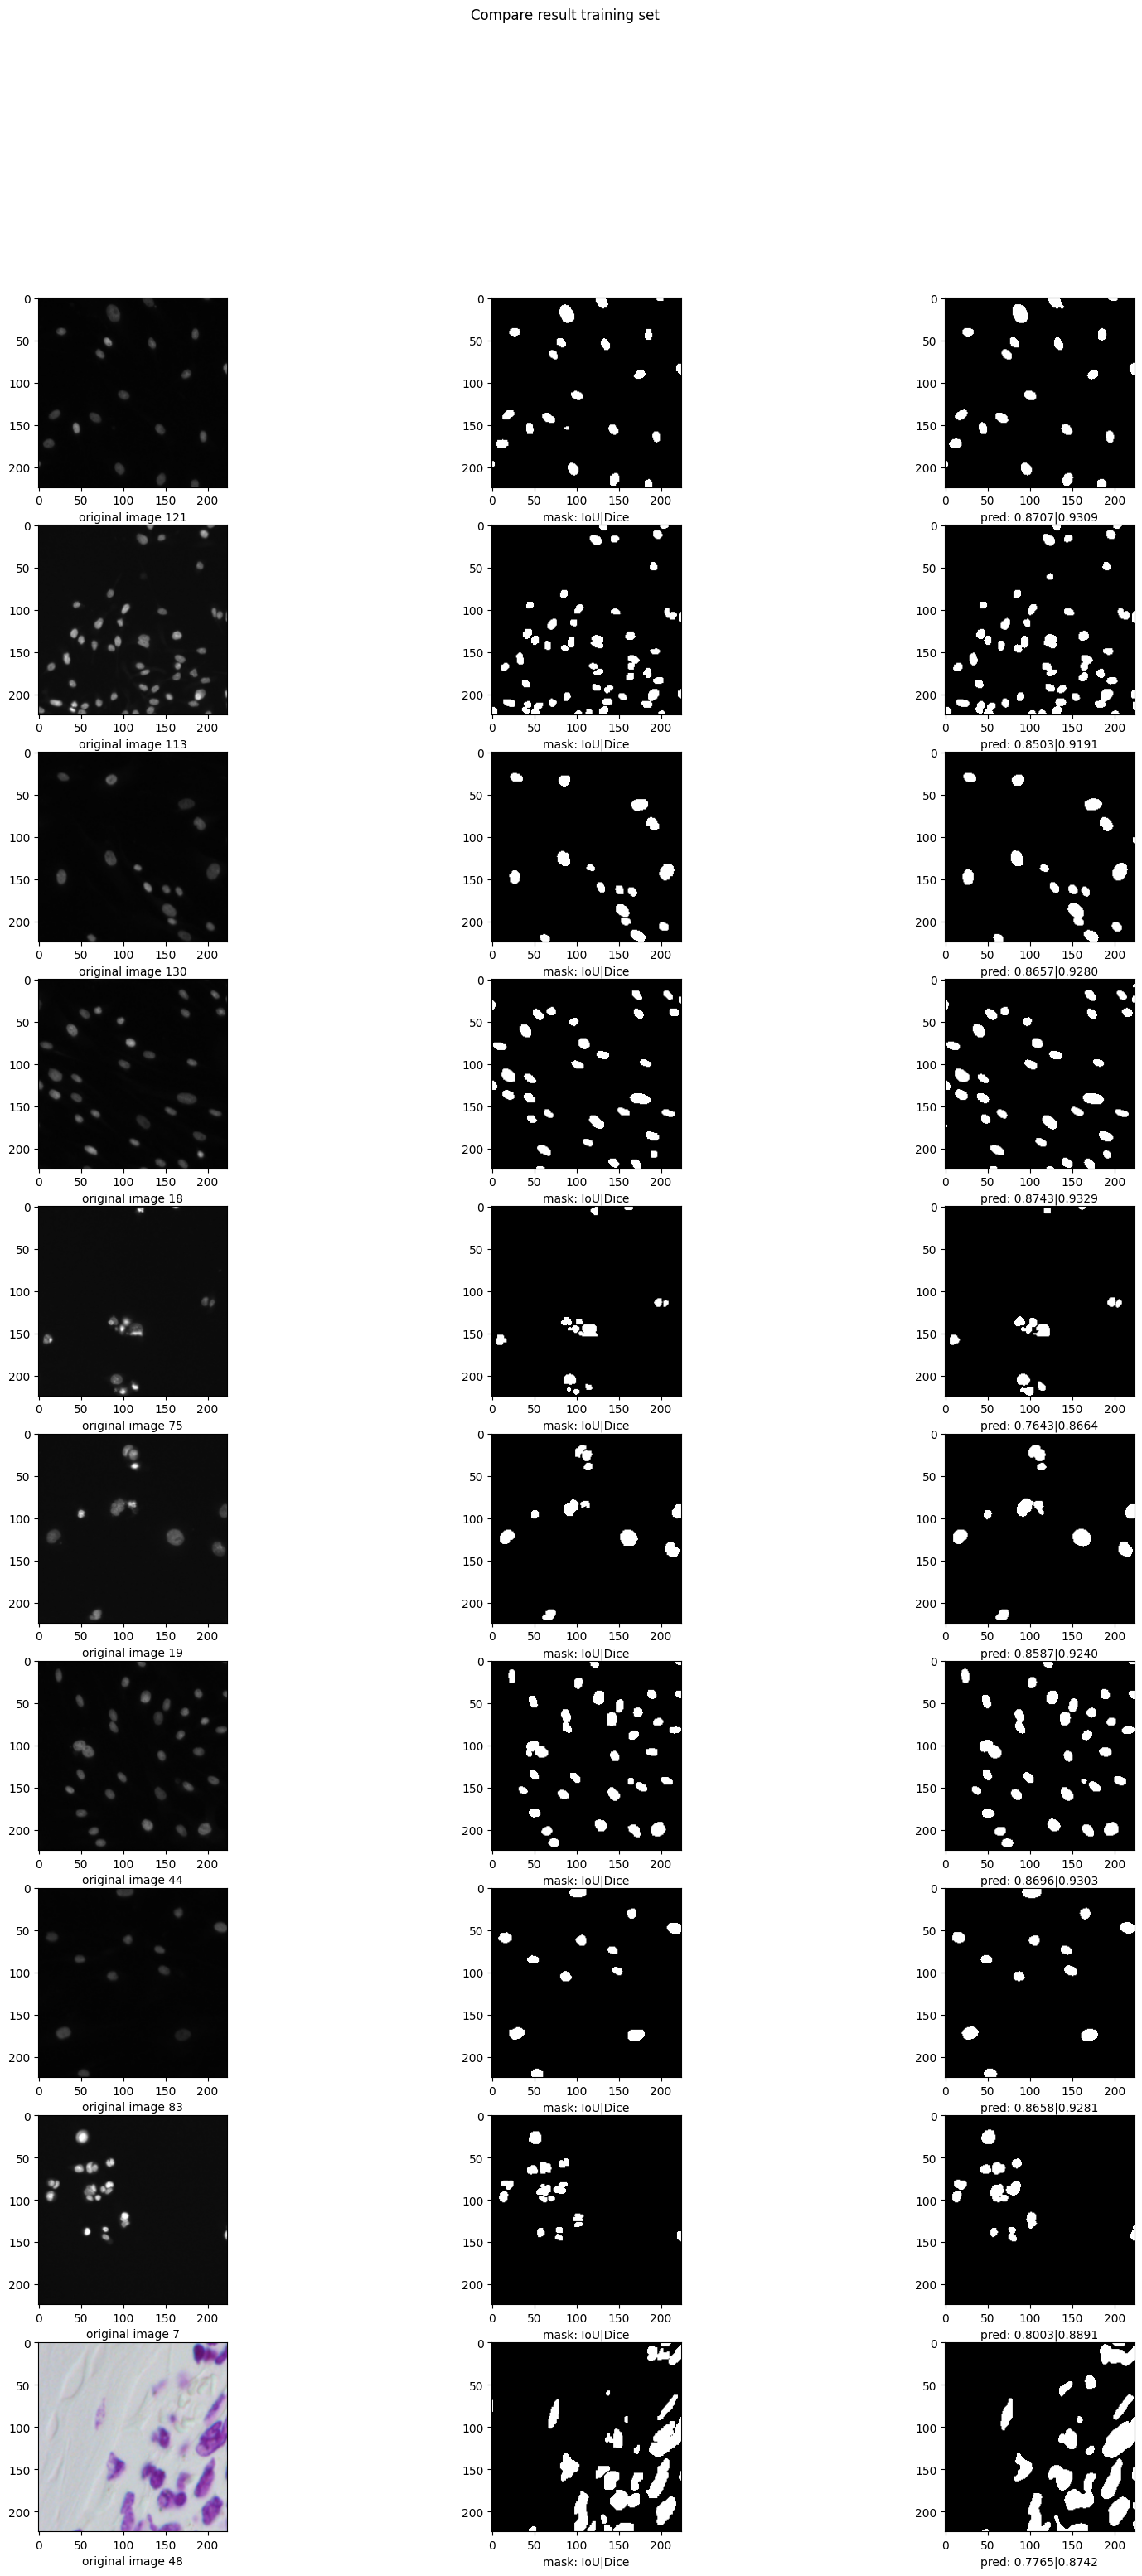

In [ ]:
reset_seed()
idx = random.randint(0, len(test_data))

model.eval()
# preds_train = new_model.predict(X_train[:int(X_train.shape[0]*0.9)], verbose=1)
# preds_val = new_model.predict(X_train[int(X_train.shape[0]*0.9):], verbose=1)
#preds_test = model.predict(X_test, verbose=1)

size_samples = 10
random_list = np.random.randint(len(test_data),size = size_samples)
#random_list = np.arange(len(test_ds))
fg , ax = plt.subplots(10,3,figsize = (20,35))
fg.suptitle("Compare result training set")

for stt,ix in enumerate(random_list):
    X_test, y_test = test_data[ix]
    ax[stt,0].imshow(X_test.transpose(0,2).transpose(0,1).cpu())
    ax[stt,0].set_xlabel("original image {}".format(ix))
    ax[stt,1].imshow(y_test, cmap = 'gray')
    ax[stt,1].set_xlabel("mask: IoU|Dice")
    with torch.no_grad():
        model.eval()
        pred = model(X_test.unsqueeze(0).cuda())
        tmp = pred.detach().cpu()
        tmp2 = y_test.detach().cpu()
        iou = classwise_iou(tmp, tmp2)
        dice = classwise_f1(tmp, tmp2)
        pred = torch.argmax(pred, dim=1)
    ax[stt,2].imshow(pred.squeeze(0).cpu(), cmap = 'gray')
    ax[stt,2].set_xlabel(f"pred: {iou:.4f}|{dice:.4f}")

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np
import cv2

def visualize_prediction_VT(dataset, idx, save_dir, save_name):
    plt.figure(figsize=(6, 6))  # Chỉnh kích thước phù hợp với bố cục
    font_size = 12  # Font size cho tiêu đề

    # Load dataset images and masks
    x_list, y_list = [], []
    for i in idx:
        x, y = dataset[i]
        x_list.append(x.unsqueeze(0))
        y_list.append(y.unsqueeze(0))

    x = torch.cat(x_list).cuda()
    y = torch.cat(y_list).cuda()

    # Set model to evaluation mode
    model.eval()

    # Get predictions
    with torch.no_grad():
        y_pred = model(x).data

    # Take argmax along the channel dimension and squeeze to remove batch dimension
    y_pred = torch.argmax(y_pred, dim=1).squeeze().cpu().numpy().astype(np.uint8)
    y_gt = y.squeeze().cpu().numpy().astype(np.uint8)

    # Hiển thị ảnh, ground truth và predicted mask
    for i in range(len(idx)):
        xa = x[i].permute(1, 2, 0).cpu().numpy()
        xa = (xa - xa.min()) / (xa.max() - xa.min())
        xa = (xa * 255).astype(np.uint8)
        xa = cv2.cvtColor(xa, cv2.COLOR_BGR2RGB)

        ya = (y_gt[i] * 255).astype(np.uint8)
        yp = (y_pred[i] * 255).astype(np.uint8)

        # Hình ảnh gốc
        plt.subplot(len(idx), 3, 3 * i + 1)
        if i == 0:
            plt.title("Image", fontsize=font_size)
        plt.imshow(xa)
        plt.axis('off')

        # Ground truth mask
        plt.subplot(len(idx), 3, 3 * i + 2)
        if i == 0:
            plt.title("Ground Truth", fontsize=font_size)
        plt.imshow(ya, cmap='gray')
        plt.axis('off')

        # Predicted mask
        plt.subplot(len(idx), 3, 3 * i + 3)
        if i == 0:
            plt.title("Predicted Mask", fontsize=font_size)
        plt.imshow(yp, cmap='gray')
        plt.axis('off')



    plt.subplots_adjust(wspace=0.05, hspace=0.05)  # Giảm khoảng cách giữa các cột và hàng

    save_path = os.path.join(save_dir, save_name)
    plt.savefig(save_path, bbox_inches="tight")

    print(f"✅ Saved grid figure: {save_path}")
    plt.show()

✅ Saved grid figure: 


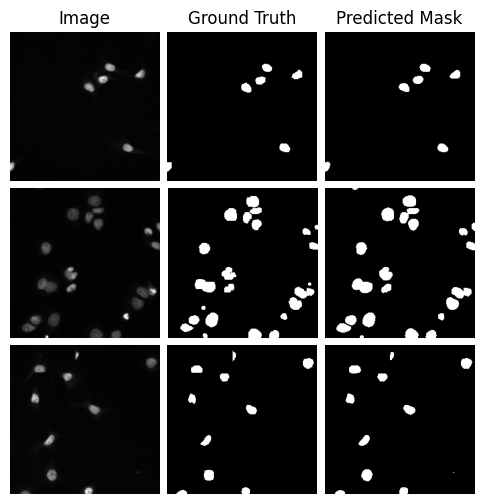

In [ ]:
visualize_prediction_VT(dataset=test_data, idx=[10,22,30],save_dir="", save_name = "" )

In [ ]:
import torch

def get_model_size_mb(model):
    """Tính kích thước mô hình (MB) dựa trên tham số."""
    param_size = 0
    buffer_size = 0

    for param in model.parameters():
        param_size += param.nelement() * param.element_size()
    for buffer in model.buffers():
        buffer_size += buffer.nelement() * buffer.element_size()

    size_all_mb = (param_size + buffer_size) / 1024**2
    return size_all_mb
model = UNet_RABM(num_classes=2, base_ch=[64,128,256,512]).cuda()
print(f"Model size: {get_model_size_mb(model):.2f} MB")